# Simple perceptron

A threshold-unit analysis of input scale, weight direction and the decision boundary. This model performs inference with specified weights; it does not learn from examples.

## Model

The score is the dot product `x @ w`. The output is 1 when the score is at least 1, and 0 otherwise. This is equivalent to a zero-threshold unit with a fixed bias of −1. The score is not a probability.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
print('NumPy:', np.__version__)


NumPy: 2.4.4


In [2]:
def predict(inputs, weights, threshold=1.0):
    score = float(np.asarray(inputs) @ np.asarray(weights))
    return score, int(score >= threshold)

cases = [
    ('Reference positive weight', [45,25], [0.7,0.1], 1.0),
    ('Reference negative weight', [45,25], [-0.7,0.1], 1.0),
    ('Smaller inputs', [0.45,0.25], [0.7,0.1], 1.0),
    ('Below threshold', [1,0], [0.7,0.1], 1.0),
    ('Exactly at threshold', [0,10], [0.7,0.1], 1.0),
    ('Threshold raised', [45,25], [0.7,0.1], 35.0)
]
rows=[]
for label, x, w, threshold in cases:
    score, prediction=predict(x,w,threshold)
    rows.append({'Case':label,'Inputs':str(x),'Weights':str(w),'Threshold':threshold,'Score':score,'Output':prediction})
results=pd.DataFrame(rows)
display(results)
assert results.Output.tolist()==[1,0,0,0,1,0]


Case,Inputs,Weights,Threshold,Score,Output
Reference positive weight,"[45, 25]","[0.7, 0.1]",1.0,34.00,1
Reference negative weight,"[45, 25]","[-0.7, 0.1]",1.0,-29.00,0
Smaller inputs,"[0.45, 0.25]","[0.7, 0.1]",1.0,0.34,0
Below threshold,"[1, 0]","[0.7, 0.1]",1.0,0.70,0
Exactly at threshold,"[0, 10]","[0.7, 0.1]",1.0,1.00,1
Threshold raised,"[45, 25]","[0.7, 0.1]",35.0,34.00,0


## Decision boundary

For weights [0.7, 0.1], the boundary is `0.7x₁ + 0.1x₂ = 1`. Changing a weight changes its orientation; changing the threshold translates it. Scaling the inputs without adjusting the model can change the output.

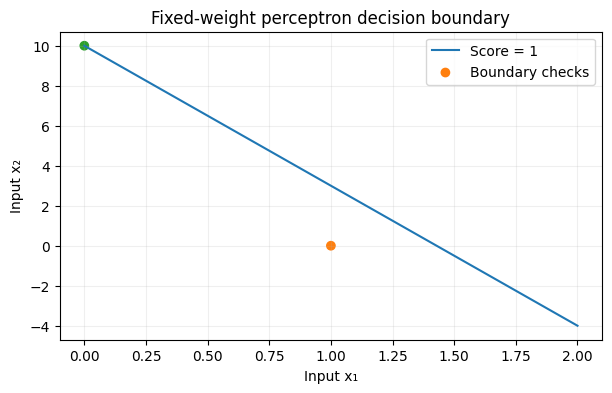

In [3]:
x1=np.linspace(0,2,100)
fig,ax=plt.subplots(figsize=(7,4))
ax.plot(x1,(1-0.7*x1)/0.1,label='Score = 1')
ax.scatter([1,0],[0,10],color=['tab:orange','tab:green'],label='Boundary checks')
ax.set(xlabel='Input x₁',ylabel='Input x₂',title='Fixed-weight perceptron decision boundary')
ax.legend(); ax.grid(alpha=0.2); plt.show()


## Interpretation

The reference score changes from 34 to −29 when the first weight changes sign, switching the output from 1 to 0. A score of exactly 1 produces class 1 because the threshold is inclusive. The smaller-input case produces a score of 0.34 and class 0. These checks establish the implemented decision rule, but provide no estimate of predictive accuracy: no labelled training set or optimisation is involved.

## Provenance and reproducibility

Adapted from the reference notebooks credited to Dr Mike Lakoju. The implementations retain the reference inputs and model structure; corrections and extensions are identified above. All data are defined in code. Cells were executed sequentially in an independent Python namespace, with outputs embedded. Analysis and editorial preparation used AI assistance.
